#  EDA  #

Importing necessary libraries

In [140]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [141]:
import warnings
warnings.filterwarnings('ignore')

Loading the Titanic dataset and displaying the first few rows

In [142]:
df = pd.read_csv("titanic.csv")
df.head()

,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,survived
0,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,1
1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,1
2,1,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,0
3,1,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,0
4,1,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,0


Summary statistics

In [143]:
df.describe()

,pclass,age,sibsp,parch,fare,survived
count,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000,1309.000000
mean,2.294882,29.881135,0.498854,0.385027,33.295479,0.381971
std,0.837836,14.413500,1.041658,0.865560,51.758668,0.486055
min,1.000000,0.166700,0.000000,0.000000,0.000000,0.000000
25%,2.000000,21.000000,0.000000,0.000000,7.895800,0.000000
50%,3.000000,28.000000,0.000000,0.000000,14.454200,0.000000
75%,3.000000,39.000000,1.000000,0.000000,31.275000,1.000000
max,3.000000,80.000000,8.000000,9.000000,512.329200,1.000000


information

In [144]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    1309 non-null   int64  
 1   name      1309 non-null   object 
 2   sex       1309 non-null   object 
 3   age       1046 non-null   float64
 4   sibsp     1309 non-null   int64  
 5   parch     1309 non-null   int64  
 6   ticket    1309 non-null   object 
 7   fare      1308 non-null   float64
 8   cabin     295 non-null    object 
 9   embarked  1307 non-null   object 
 10  survived  1309 non-null   int64  
dtypes: float64(2), int64(4), object(5)
memory usage: 112.6+ KB


missing value analysis

In [145]:
df.isnull().sum()

pclass         0
name           0
sex            0
age          263
sibsp          0
parch          0
ticket         0
fare           1
cabin       1014
embarked       2
survived       0
dtype: int64

Handling missing values in 'age' and 'embarked' columns

In [146]:
df['age']=df['age'].fillna(df['age'].median())
df['embarked']=df['embarked'].fillna(df['embarked'].mode()[0])

Checking if there are any remaining missing values


In [147]:
df.isnull().sum().sum()

1015

Final check on dataset information

In [148]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    1309 non-null   int64  
 1   name      1309 non-null   object 
 2   sex       1309 non-null   object 
 3   age       1309 non-null   float64
 4   sibsp     1309 non-null   int64  
 5   parch     1309 non-null   int64  
 6   ticket    1309 non-null   object 
 7   fare      1308 non-null   float64
 8   cabin     295 non-null    object 
 9   embarked  1309 non-null   object 
 10  survived  1309 non-null   int64  
dtypes: float64(2), int64(4), object(5)
memory usage: 112.6+ KB


Unique values in the 'embarked' column

In [149]:
df['embarked'].unique()

array(['S', 'C', 'Q'], dtype=object)

Encoding 'embarked' column

In [150]:
df.embarked.replace(['S','C','Q'],[1,2,3],inplace = True)

Unique values in the 'sex' column

In [151]:
df['sex'].unique()

array(['female', 'male'], dtype=object)

Encoding 'sex' column

In [152]:
df.sex.replace(['male','female'],[1,0],inplace = True)

Dropping unnecessary columns

In [153]:
df = df.drop('name', axis=1,)
df = df.drop('ticket', axis=1,)
df = df.drop('fare', axis=1,)
df = df.drop('cabin', axis=1,)

Creating 'Family' column and dropping 'sibsp' and 'parch' columns

In [154]:
df['Family'] = df['sibsp'] + df['parch'] + 1
df = df.drop('sibsp', axis=1,)
df = df.drop('parch', axis=1,)

Converting 'age' column to integer type

In [155]:
df['age']=df['age'].astype(int)

Summary statistics after data preprocessing

In [156]:
df.describe()

,pclass,sex,age,embarked,survived,Family
count,1309.000000,1309.000000,1309.000000,1309.000000,1309.000000,1309.000000
mean,2.294882,0.644003,29.484339,1.394194,0.381971,1.883881
std,0.837836,0.478997,12.916721,0.653499,0.486055,1.583639
min,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000
25%,2.000000,0.000000,22.000000,1.000000,0.000000,1.000000
50%,3.000000,1.000000,28.000000,1.000000,0.000000,1.000000
75%,3.000000,1.000000,35.000000,2.000000,1.000000,2.000000
max,3.000000,1.000000,80.000000,3.000000,1.000000,11.000000


Final check on dataset information after preprocessing

In [157]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   pclass    1309 non-null   int64
 1   sex       1309 non-null   int64
 2   age       1309 non-null   int32
 3   embarked  1309 non-null   int64
 4   survived  1309 non-null   int64
 5   Family    1309 non-null   int64
dtypes: int32(1), int64(5)
memory usage: 56.4 KB


Boxplot visualization of numerical columns

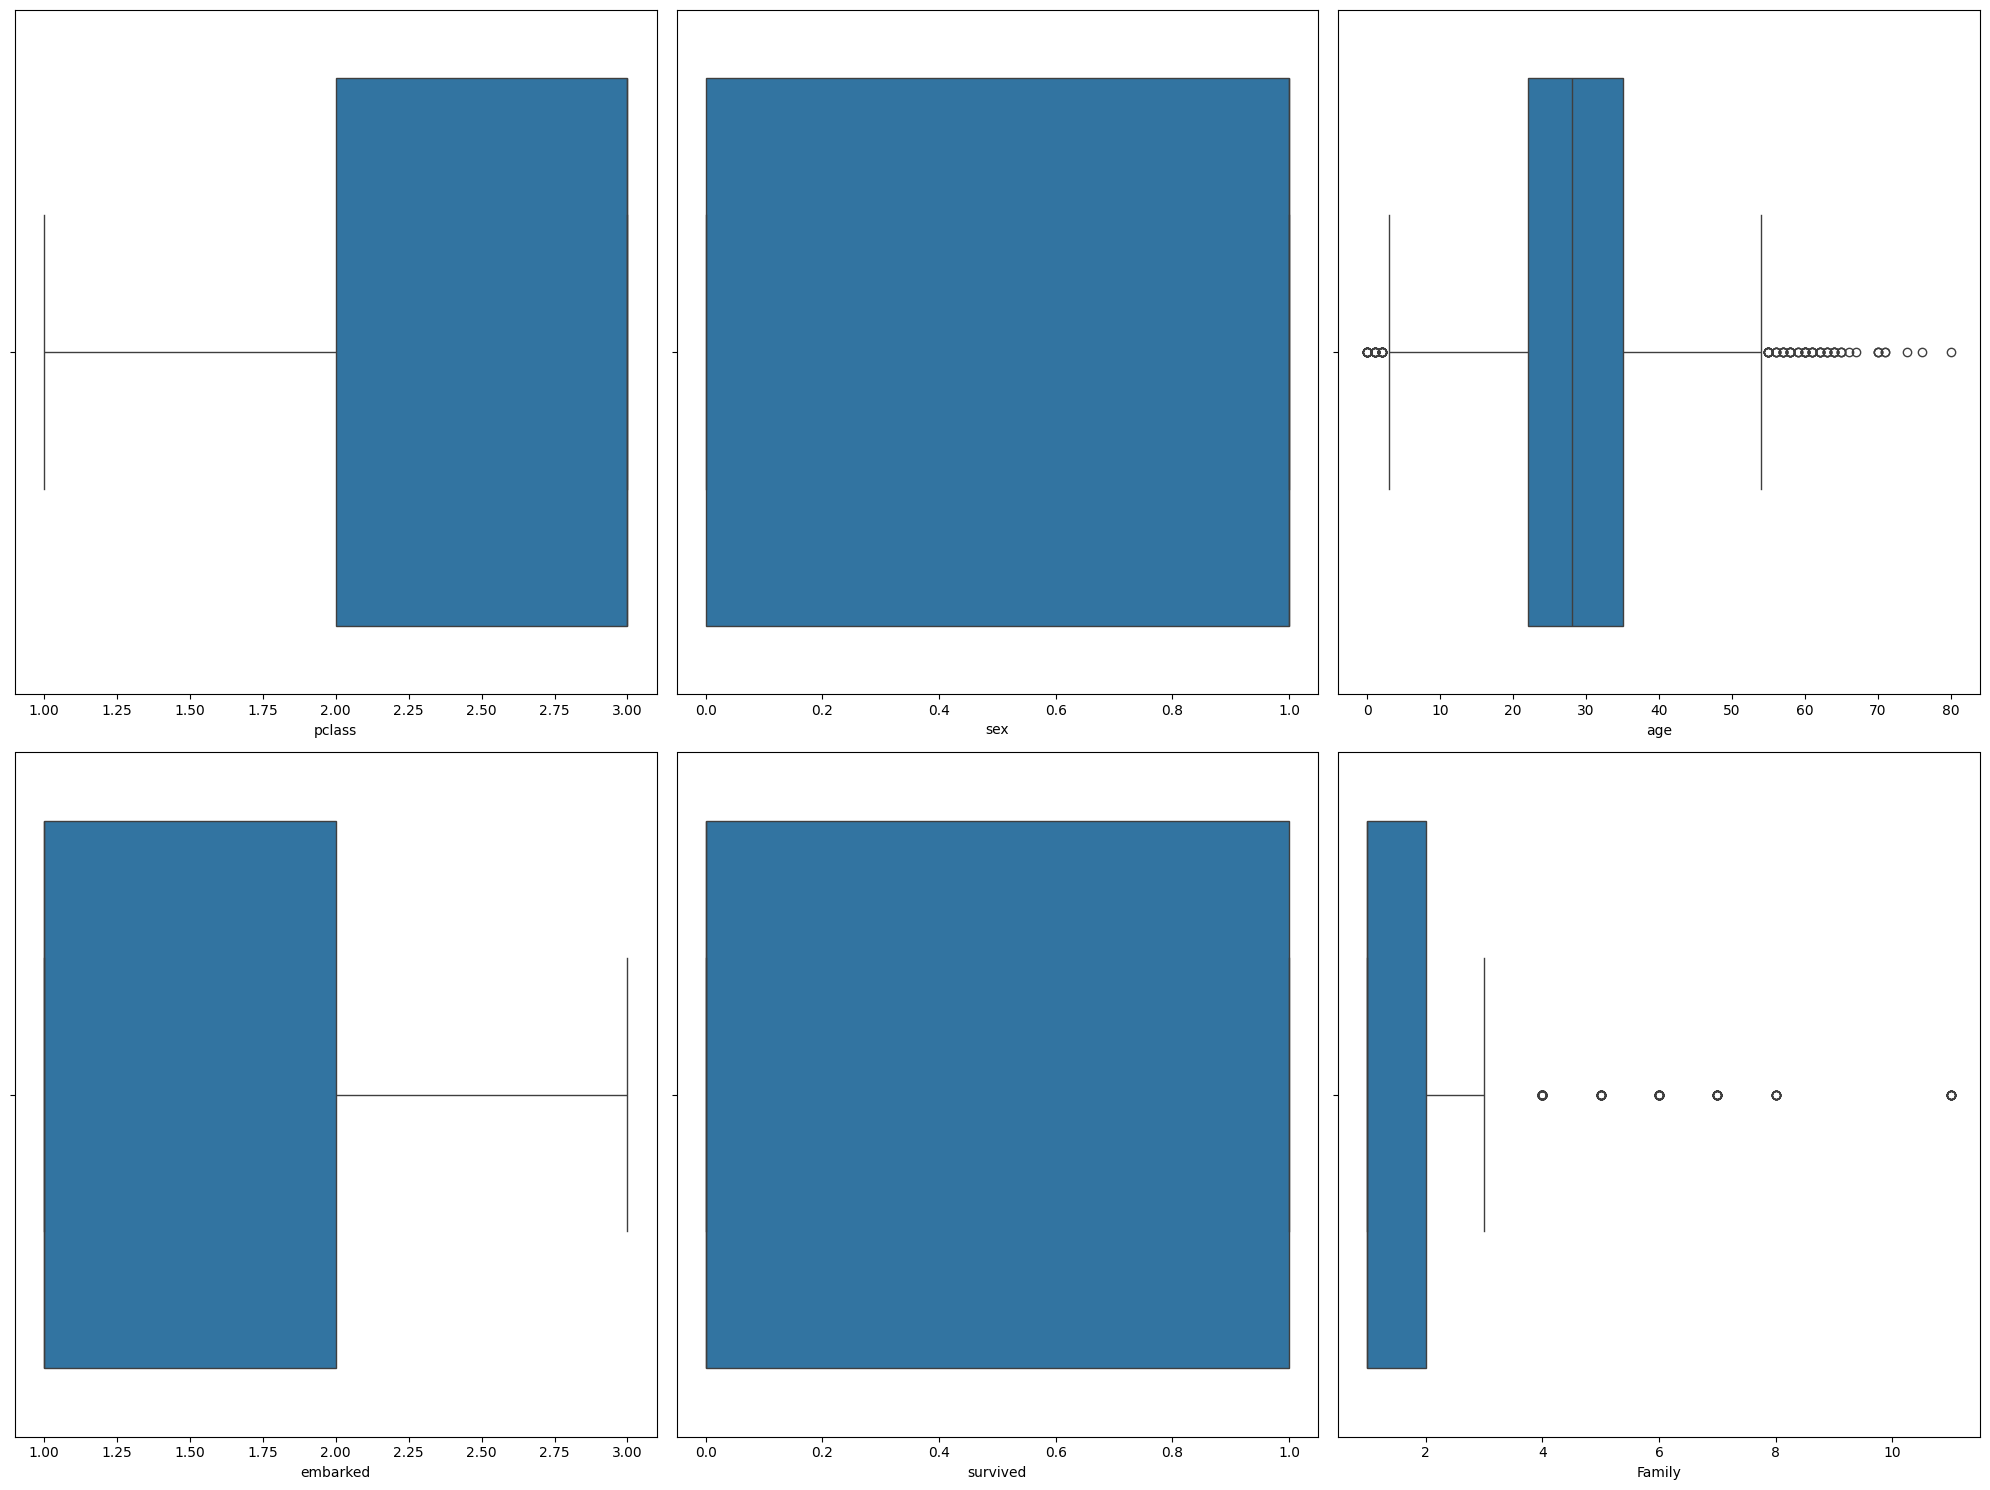

In [158]:
neumirc_columns=df.select_dtypes(include=["number"])
plt.figure(figsize=(20,15))
for i,col in enumerate(neumirc_columns):
    plt.subplot(2,3,i+1)
    sns.boxplot(x=df[col])
plt.tight_layout()
plt.show()


 Histogram visualization of numerical columns

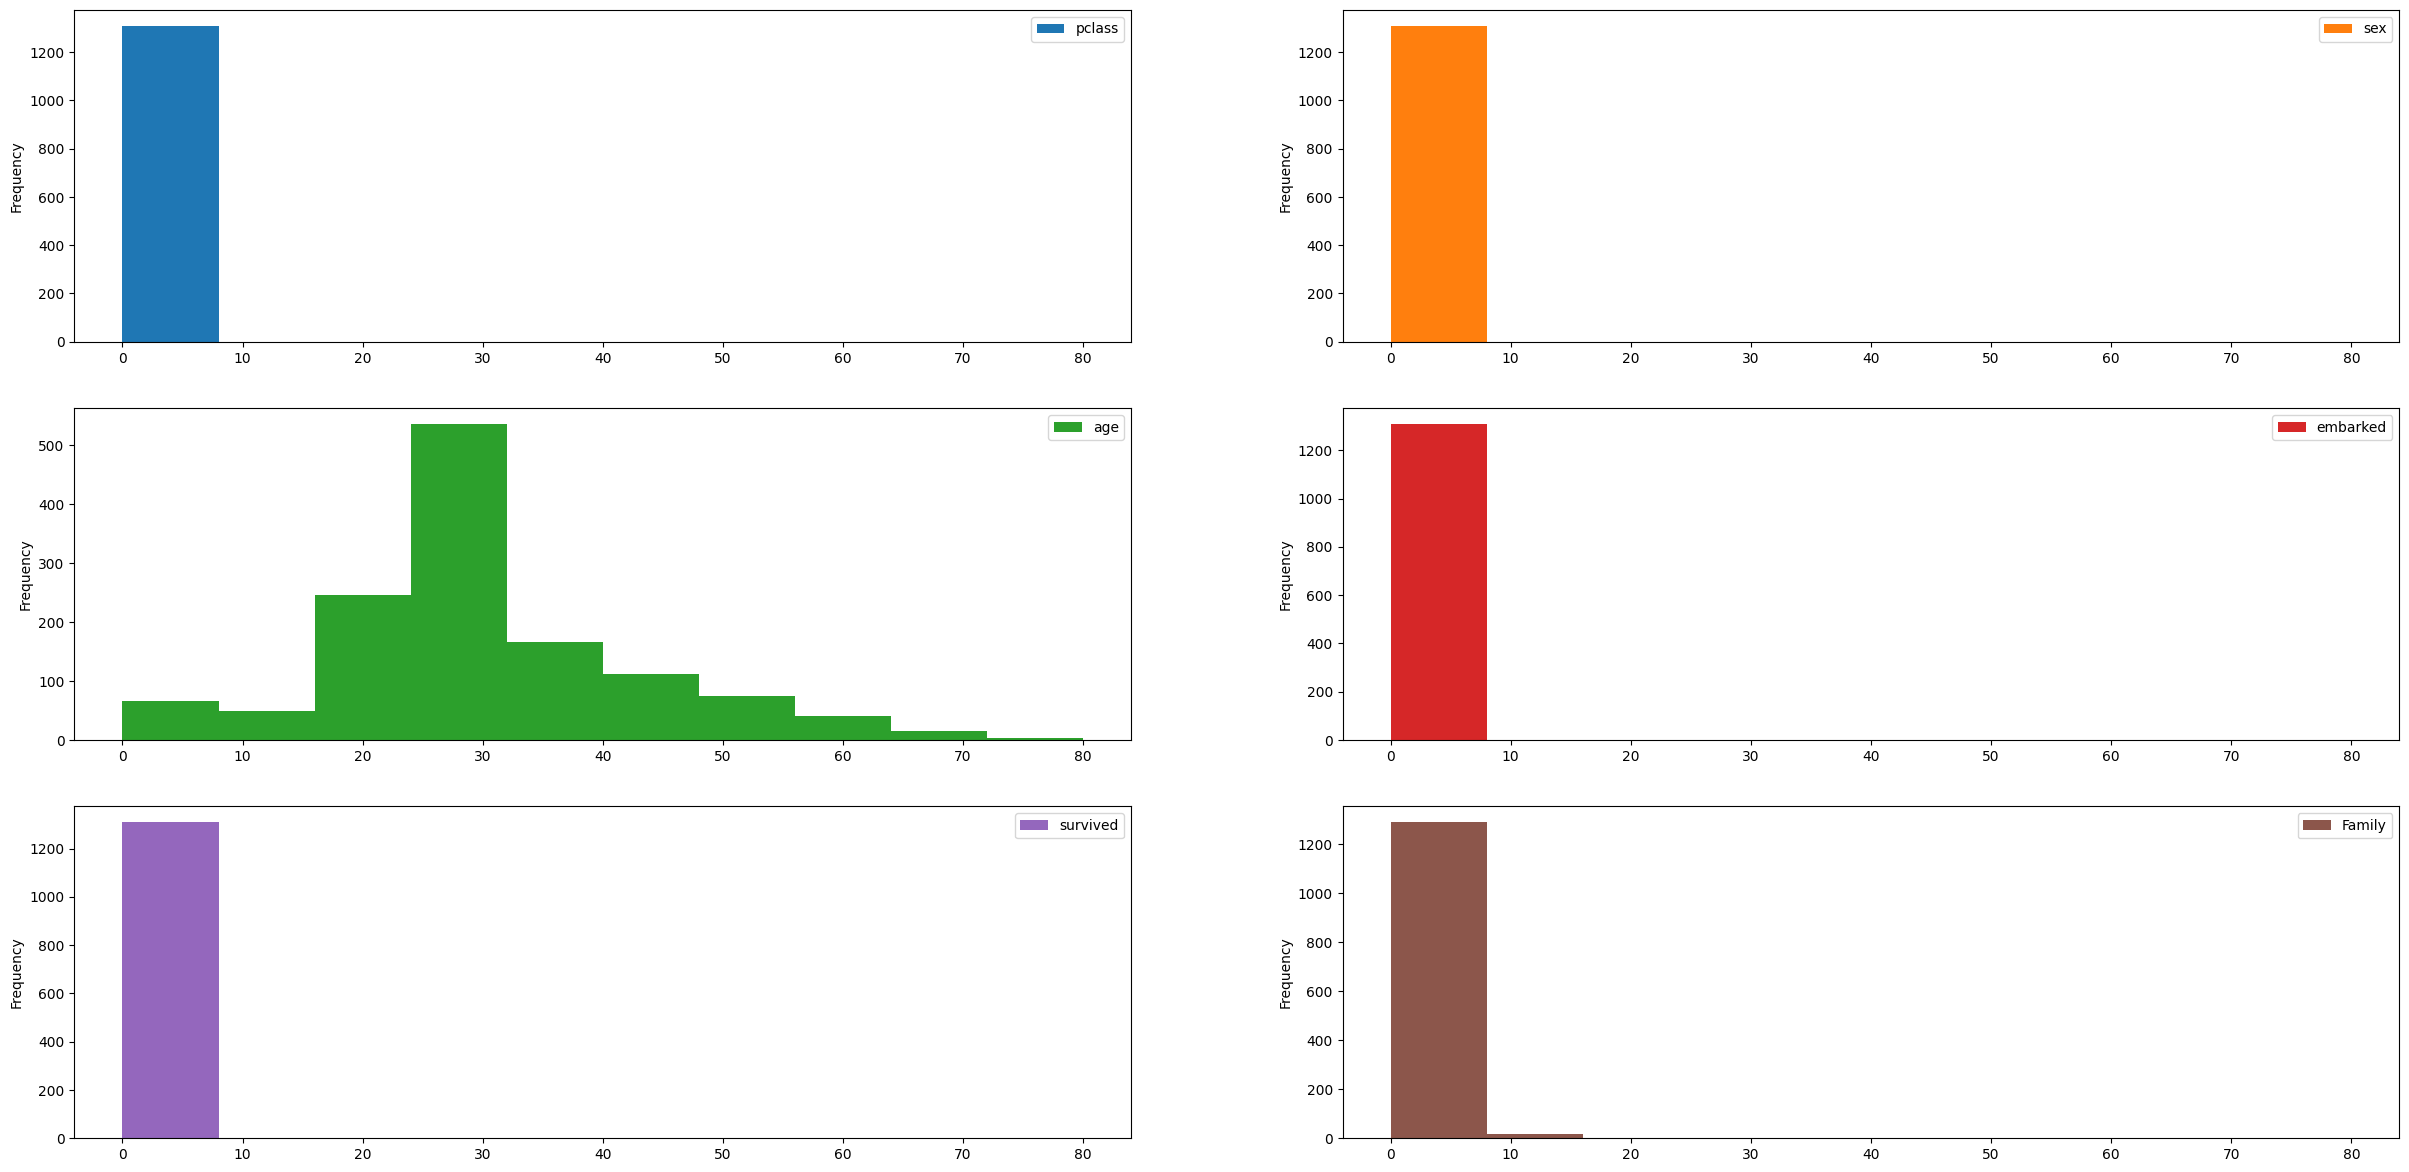

In [159]:
plt.rcParams['figure.figsize']=(30,25)
df.plot(kind='hist', bins=10, subplots=True, layout=(5,2), sharex=False, sharey=False)
plt.show()

# Data Splitting

Separating features (X) and target variable (y)

In [160]:
X = df.drop(['survived'], axis=1)
y = df['survived']

Splitting the dataset into training and testing sets

In [161]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

Checking the shapes of training and testing sets

In [162]:
X_train.shape, X_test.shape

((1047, 5), (262, 5))

Standardizing the features

In [163]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

# KNN

evaluate the K-Nearest Neighbors (KNN) classifier with varying numbers of neighbors (k) to find the optimal value. For each value of k, we train the model on the training set and evaluate its performance on the testing set using various metrics.

In [164]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
final_scores = []
for k in range(1,30):
    knn_model = KNeighborsClassifier(n_neighbors=k)
    knn_model.fit(X_train, y_train)

    # Evaluate the model
    y_pred = knn_model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    final_scores.append(accuracy)
    print(f"KNN (k={k}) :")
    print(f"Accuracy:   {round(accuracy*100,3)} %")
    print(f"Precision:  {round(precision*100,3)} %")
    print(f"Recall:     {round(recall*100,3)} %")
    print(f"F1 Score:   {round(f1*100,3)} %\n")

KNN (k=1) :
Accuracy:   77.099 %
Precision:  76.316 %
Recall:     58.0 %
F1 Score:   65.909 %

KNN (k=2) :
Accuracy:   76.336 %
Precision:  89.583 %
Recall:     43.0 %
F1 Score:   58.108 %

KNN (k=3) :
Accuracy:   78.244 %
Precision:  77.922 %
Recall:     60.0 %
F1 Score:   67.797 %

KNN (k=4) :
Accuracy:   77.099 %
Precision:  82.258 %
Recall:     51.0 %
F1 Score:   62.963 %

KNN (k=5) :
Accuracy:   77.863 %
Precision:  75.61 %
Recall:     62.0 %
F1 Score:   68.132 %

KNN (k=6) :
Accuracy:   77.863 %
Precision:  80.882 %
Recall:     55.0 %
F1 Score:   65.476 %

KNN (k=7) :
Accuracy:   78.244 %
Precision:  76.543 %
Recall:     62.0 %
F1 Score:   68.508 %

KNN (k=8) :
Accuracy:   79.389 %
Precision:  81.944 %
Recall:     59.0 %
F1 Score:   68.605 %

KNN (k=9) :
Accuracy:   78.244 %
Precision:  76.543 %
Recall:     62.0 %
F1 Score:   68.508 %

KNN (k=10) :
Accuracy:   79.389 %
Precision:  81.081 %
Recall:     60.0 %
F1 Score:   68.966 %



KNN (k=11) :
Accuracy:   79.008 %
Precision:  78.481 %
Recall:     62.0 %
F1 Score:   69.274 %

KNN (k=12) :
Accuracy:   80.534 %
Precision:  84.507 %
Recall:     60.0 %
F1 Score:   70.175 %

KNN (k=13) :
Accuracy:   81.298 %
Precision:  81.481 %
Recall:     66.0 %
F1 Score:   72.928 %

KNN (k=14) :
Accuracy:   81.298 %
Precision:  84.0 %
Recall:     63.0 %
F1 Score:   72.0 %

KNN (k=15) :
Accuracy:   80.153 %
Precision:  80.769 %
Recall:     63.0 %
F1 Score:   70.787 %

KNN (k=16) :
Accuracy:   81.679 %
Precision:  86.111 %
Recall:     62.0 %
F1 Score:   72.093 %

KNN (k=17) :
Accuracy:   82.061 %
Precision:  83.544 %
Recall:     66.0 %
F1 Score:   73.743 %

KNN (k=18) :
Accuracy:   80.916 %
Precision:  84.722 %
Recall:     61.0 %
F1 Score:   70.93 %

KNN (k=19) :
Accuracy:   81.679 %
Precision:  84.211 %
Recall:     64.0 %
F1 Score:   72.727 %

KNN (k=20) :
Accuracy:   81.298 %
Precision:  84.932 %
Recall:     62.0 %
F1 Score:   71.676 %

KNN (k=21) :
Accuracy:   81.679 %
Precision: 

Optimal Model Accuracy

In [165]:
print('Model accuracy score: ',round(max(final_scores)*100,3),'%', 'for k = ',final_scores.index(max(final_scores))+1)

Model accuracy score:  82.061 % for k =  17


evaluation of the KNN classifier using different distance metrics, namely Euclidean, Manhattan, and Chebyshev distances. The performance metrics including accuracy, precision, recall, and F1-score are reported for each distance metric.

In [166]:
# Define distance metrics
distance_metrics = ['euclidean', 'manhattan', 'chebyshev']

# Experiment with different distance metrics
for metric in distance_metrics:
    print(f"Distance Metric: {metric} :\n")
    knn_model = KNeighborsClassifier(n_neighbors=17, metric=metric)
    knn_model.fit(X_train, y_train)

    # Evaluate the model
    y_pred = knn_model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
   
    print(f"Accuracy:   {round(accuracy*100,3)} %")
    print(f"Precision:  {round(precision*100,3)} %")
    print(f"Recall:     {round(recall*100,3)} %")
    print(f"F1 Score:   {round(f1*100,3)} %\n\n")

Distance Metric: euclidean :

Accuracy:   82.061 %
Precision:  83.544 %
Recall:     66.0 %
F1 Score:   73.743 %


Distance Metric: manhattan :

Accuracy:   80.534 %
Precision:  81.013 %
Recall:     64.0 %
F1 Score:   71.508 %


Distance Metric: chebyshev :

Accuracy:   82.061 %
Precision:  84.416 %
Recall:     65.0 %
F1 Score:   73.446 %




# Here's a brief explanation of each distance metric :

## Euclidean distance : 
Measures the straight-line distance between two points in Euclidean space. It is the default distance metric used in KNN.


## Manhattan distance : 
it calculates the distance as the sum of the absolute differences between the coordinates of the points.


## Chebyshev distance :
it calculates the distance by taking the maximum absolute difference between the coordinates of the points.

Training the K-Nearest Neighbors (KNN) Classifier

In [167]:
knn = KNeighborsClassifier(n_neighbors = 17)
knn.fit(X_train, y_train)
pred = knn.predict(X_test)


Confusion Matrix Visualization

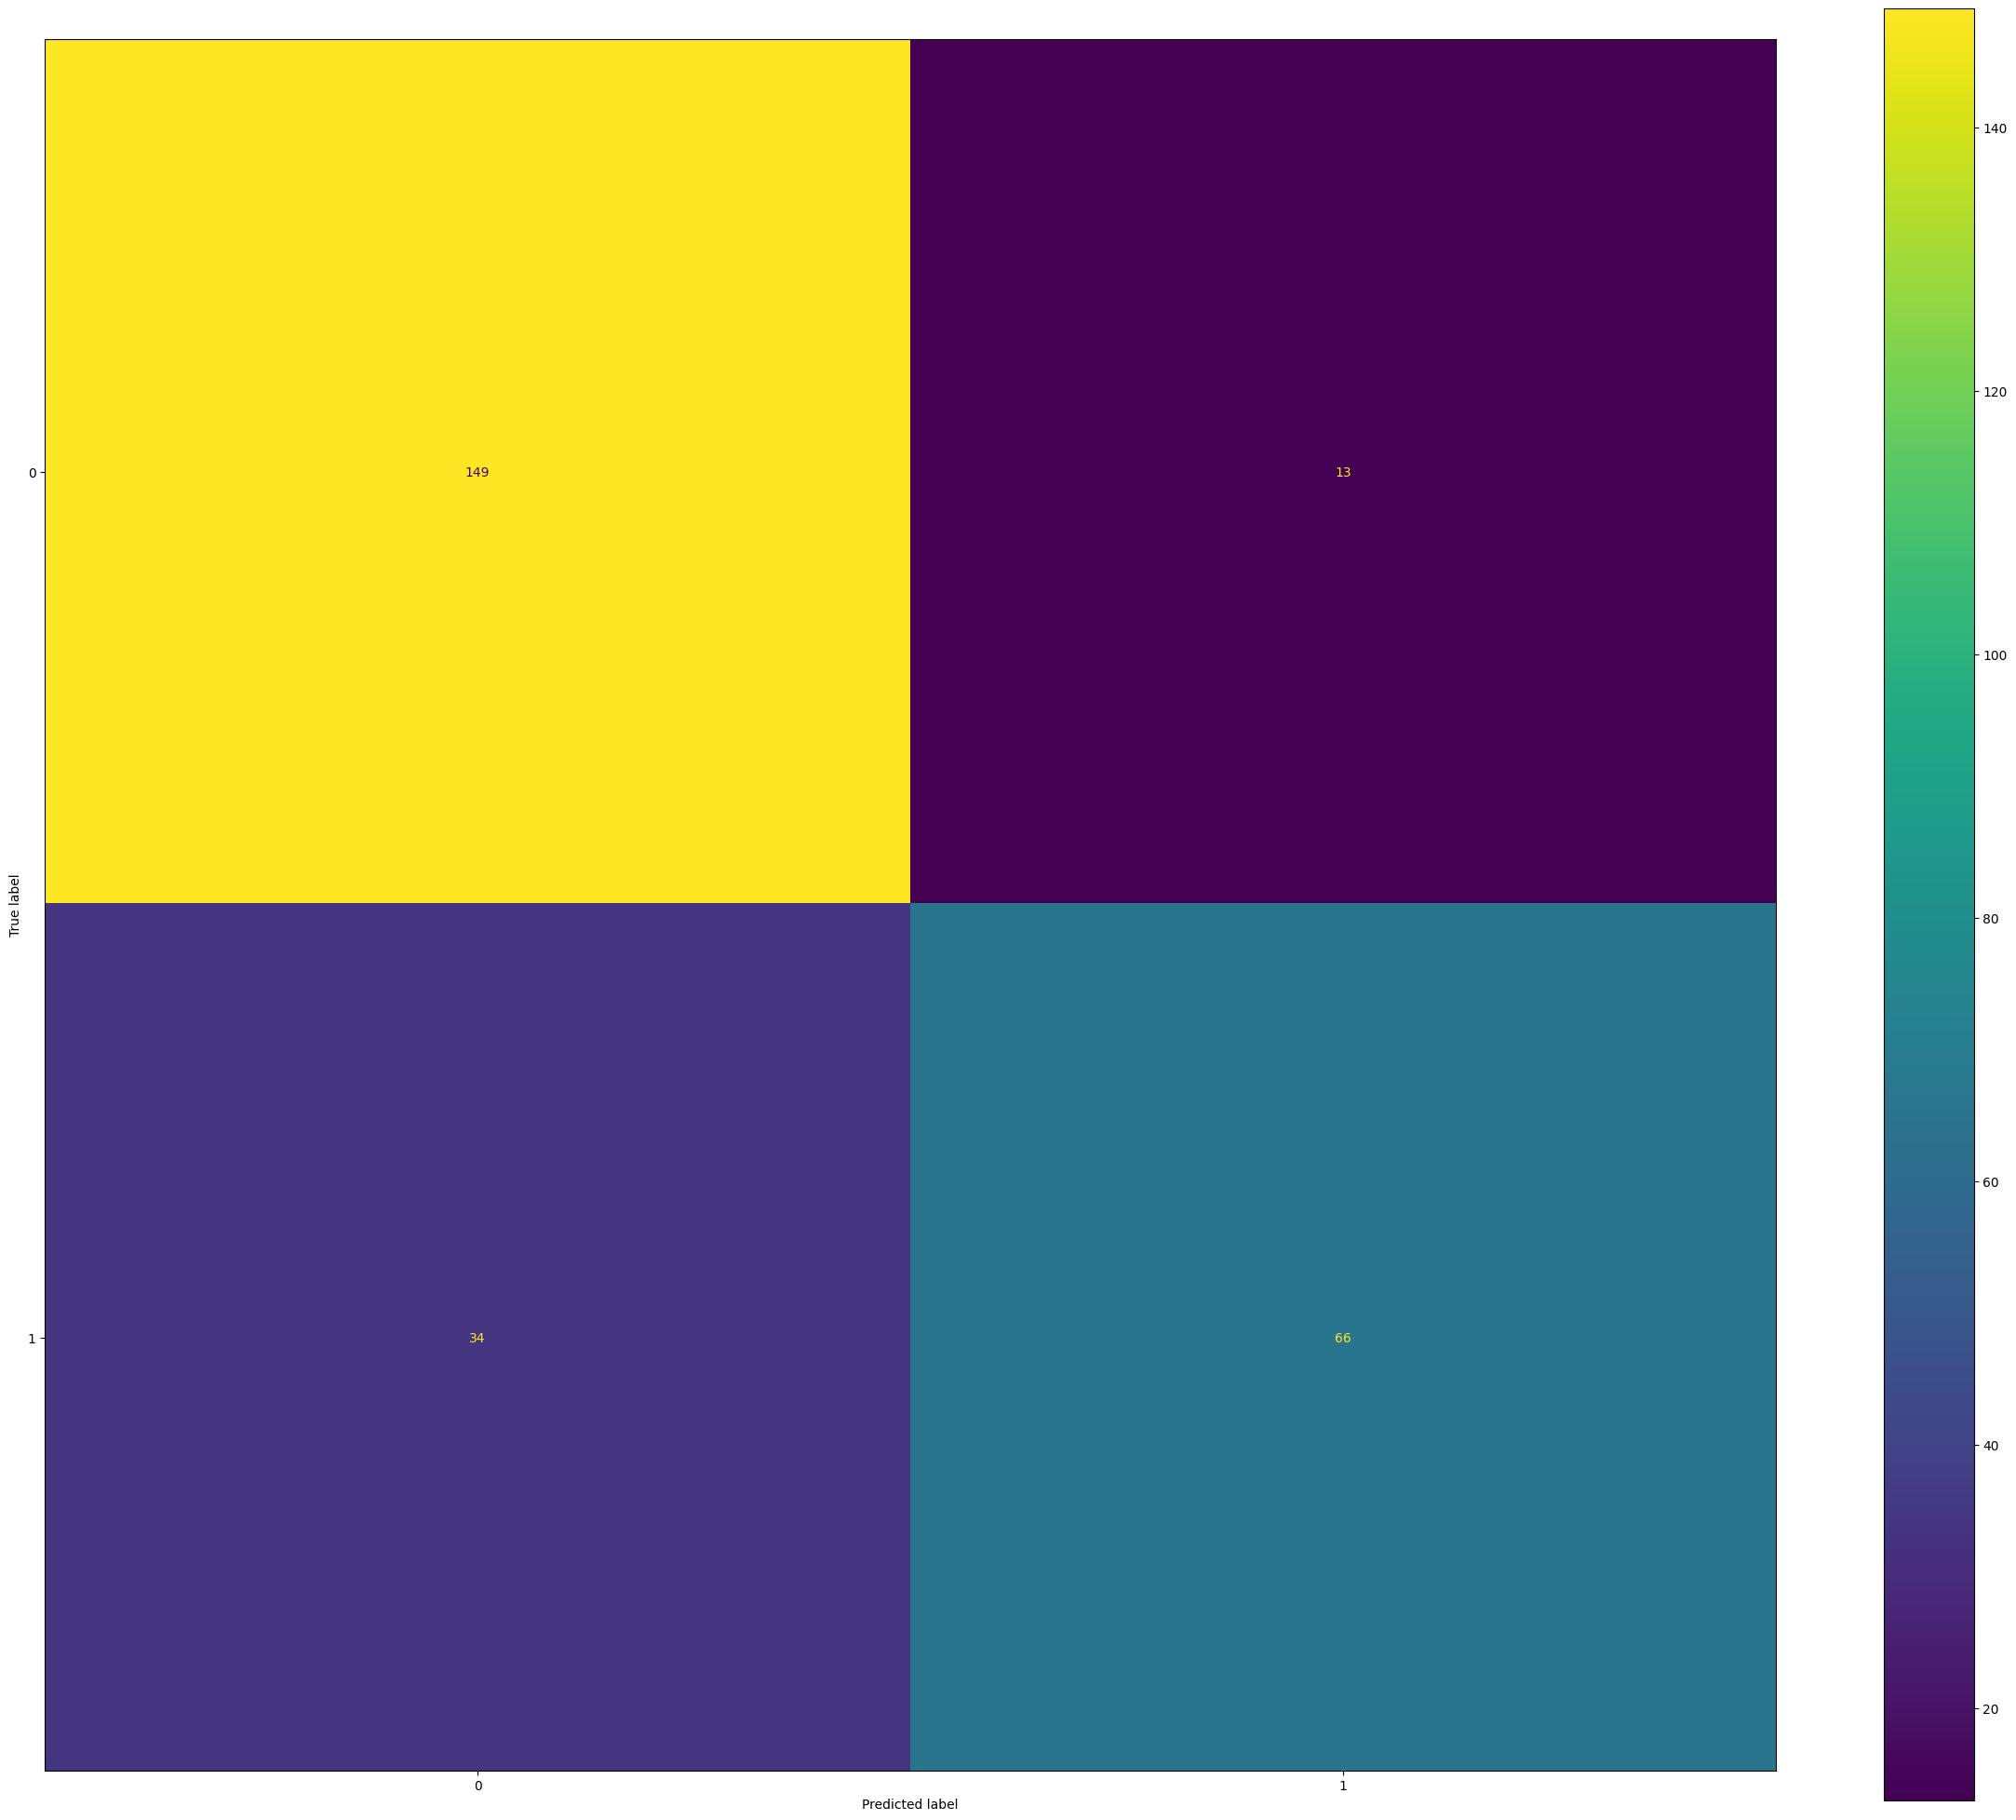

In [168]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
con = confusion_matrix(y_test, knn.predict(X_test))
disp = ConfusionMatrixDisplay(con)
disp.plot()

# KNN On Test Data 

Loading the Test Dataset,
displaying the first few rows.


In [169]:
test_df = pd.read_csv('test.csv')
test_df.head()

,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [170]:
test_df.describe()

,pclass,age,sibsp,parch,fare
count,19.000000,18.000000,19.000000,19.000000,19.000000
mean,2.421053,32.638889,0.526316,0.105263,20.066232
std,0.768533,14.576175,0.611775,0.315302,20.221058
min,1.000000,14.000000,0.000000,0.000000,7.000000
25%,2.000000,22.250000,0.000000,0.000000,7.862500
50%,3.000000,27.000000,0.000000,0.000000,9.687500
75%,3.000000,43.250000,1.000000,0.000000,26.000000
max,3.000000,63.000000,2.000000,1.000000,82.266700


In [171]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pclass    19 non-null     int64  
 1   name      19 non-null     object 
 2   sex       19 non-null     object 
 3   age       18 non-null     float64
 4   sibsp     19 non-null     int64  
 5   parch     19 non-null     int64  
 6   ticket    19 non-null     object 
 7   fare      19 non-null     float64
 8   cabin     2 non-null      object 
 9   embarked  19 non-null     object 
dtypes: float64(2), int64(3), object(5)
memory usage: 1.6+ KB


In [172]:
test_df.isnull().sum()

pclass       0
name         0
sex          0
age          1
sibsp        0
parch        0
ticket       0
fare         0
cabin       17
embarked     0
dtype: int64

Preprocessing the Test Dataset

In [173]:
test_df.sex.replace(['male','female'],[1,0],inplace = True)
test_df.embarked.replace(['S','C','Q'],[1,2,3],inplace = True)
test_df['age']=test_df['age'].fillna(test_df['age'].median())
test_df['age']=test_df['age'].astype(int)


test_df = test_df.drop('name', axis=1,)
test_df = test_df.drop('ticket', axis=1,)
test_df = test_df.drop('fare', axis=1,)
test_df = test_df.drop('cabin', axis=1,)





test_df['Family'] = test_df['sibsp'] + test_df['parch'] + 1
test_df = test_df.drop('sibsp', axis=1,)
test_df = test_df.drop('parch', axis=1,)


In [174]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   pclass    19 non-null     int64
 1   sex       19 non-null     int64
 2   age       19 non-null     int32
 3   embarked  19 non-null     int64
 4   Family    19 non-null     int64
dtypes: int32(1), int64(4)
memory usage: 816.0 bytes


Scaling the Test Dataset

In [175]:
test_df_scaled = sc.transform(test_df) 

Making Predictions on the Test Dataset


In [176]:
pred = knn.predict(test_df_scaled)

A new DataFrame "test_df_with_predictions" is created by concatenating the original test DataFrame with the predictions DataFrame along the columns. This DataFrame now includes the predicted 'Survived' column.

In [177]:
predictions_df = pd.DataFrame(pred, index=test_df.index, columns=['Survived'])

# Concatenate the original test DataFrame with the predictions DataFrame along the columns
test_df_with_predictions = pd.concat([test_df, predictions_df], axis=1)

 DataFrame with Predictions

In [178]:
test_df_with_predictions

,pclass,sex,age,embarked,Family,Survived
0,3,1,34,3,1,0
1,3,0,47,1,2,1
2,2,1,62,3,1,0
3,3,1,27,1,1,0
4,3,0,22,1,3,0
5,3,1,14,1,1,0
6,3,0,30,3,1,1
7,2,1,26,1,3,0
8,3,0,18,2,1,1
9,3,1,21,1,3,0


# Naive Bias

The Gaussian Naive Bayes classifier is trained and evaluated on the test set, and performance metrics including accuracy, precision, recall, and F1-score are reported.

In [179]:
from sklearn.naive_bayes import GaussianNB


gnb = GaussianNB()

gnb.fit(X_train, y_train)

y_pred = gnb.predict(X_test)



accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
   
print(f"Accuracy:   {round(accuracy*100,3)} %")
print(f"Precision:  {round(precision*100,3)} %")
print(f"Recall:     {round(recall*100,3)} %")
print(f"F1 Score:   {round(f1*100,3)} %\n\n")

Accuracy:   78.626 %
Precision:  75.581 %
Recall:     65.0 %
F1 Score:   69.892 %




Confusion Matrix Visualization for Gaussian Naive Bayes Classifier

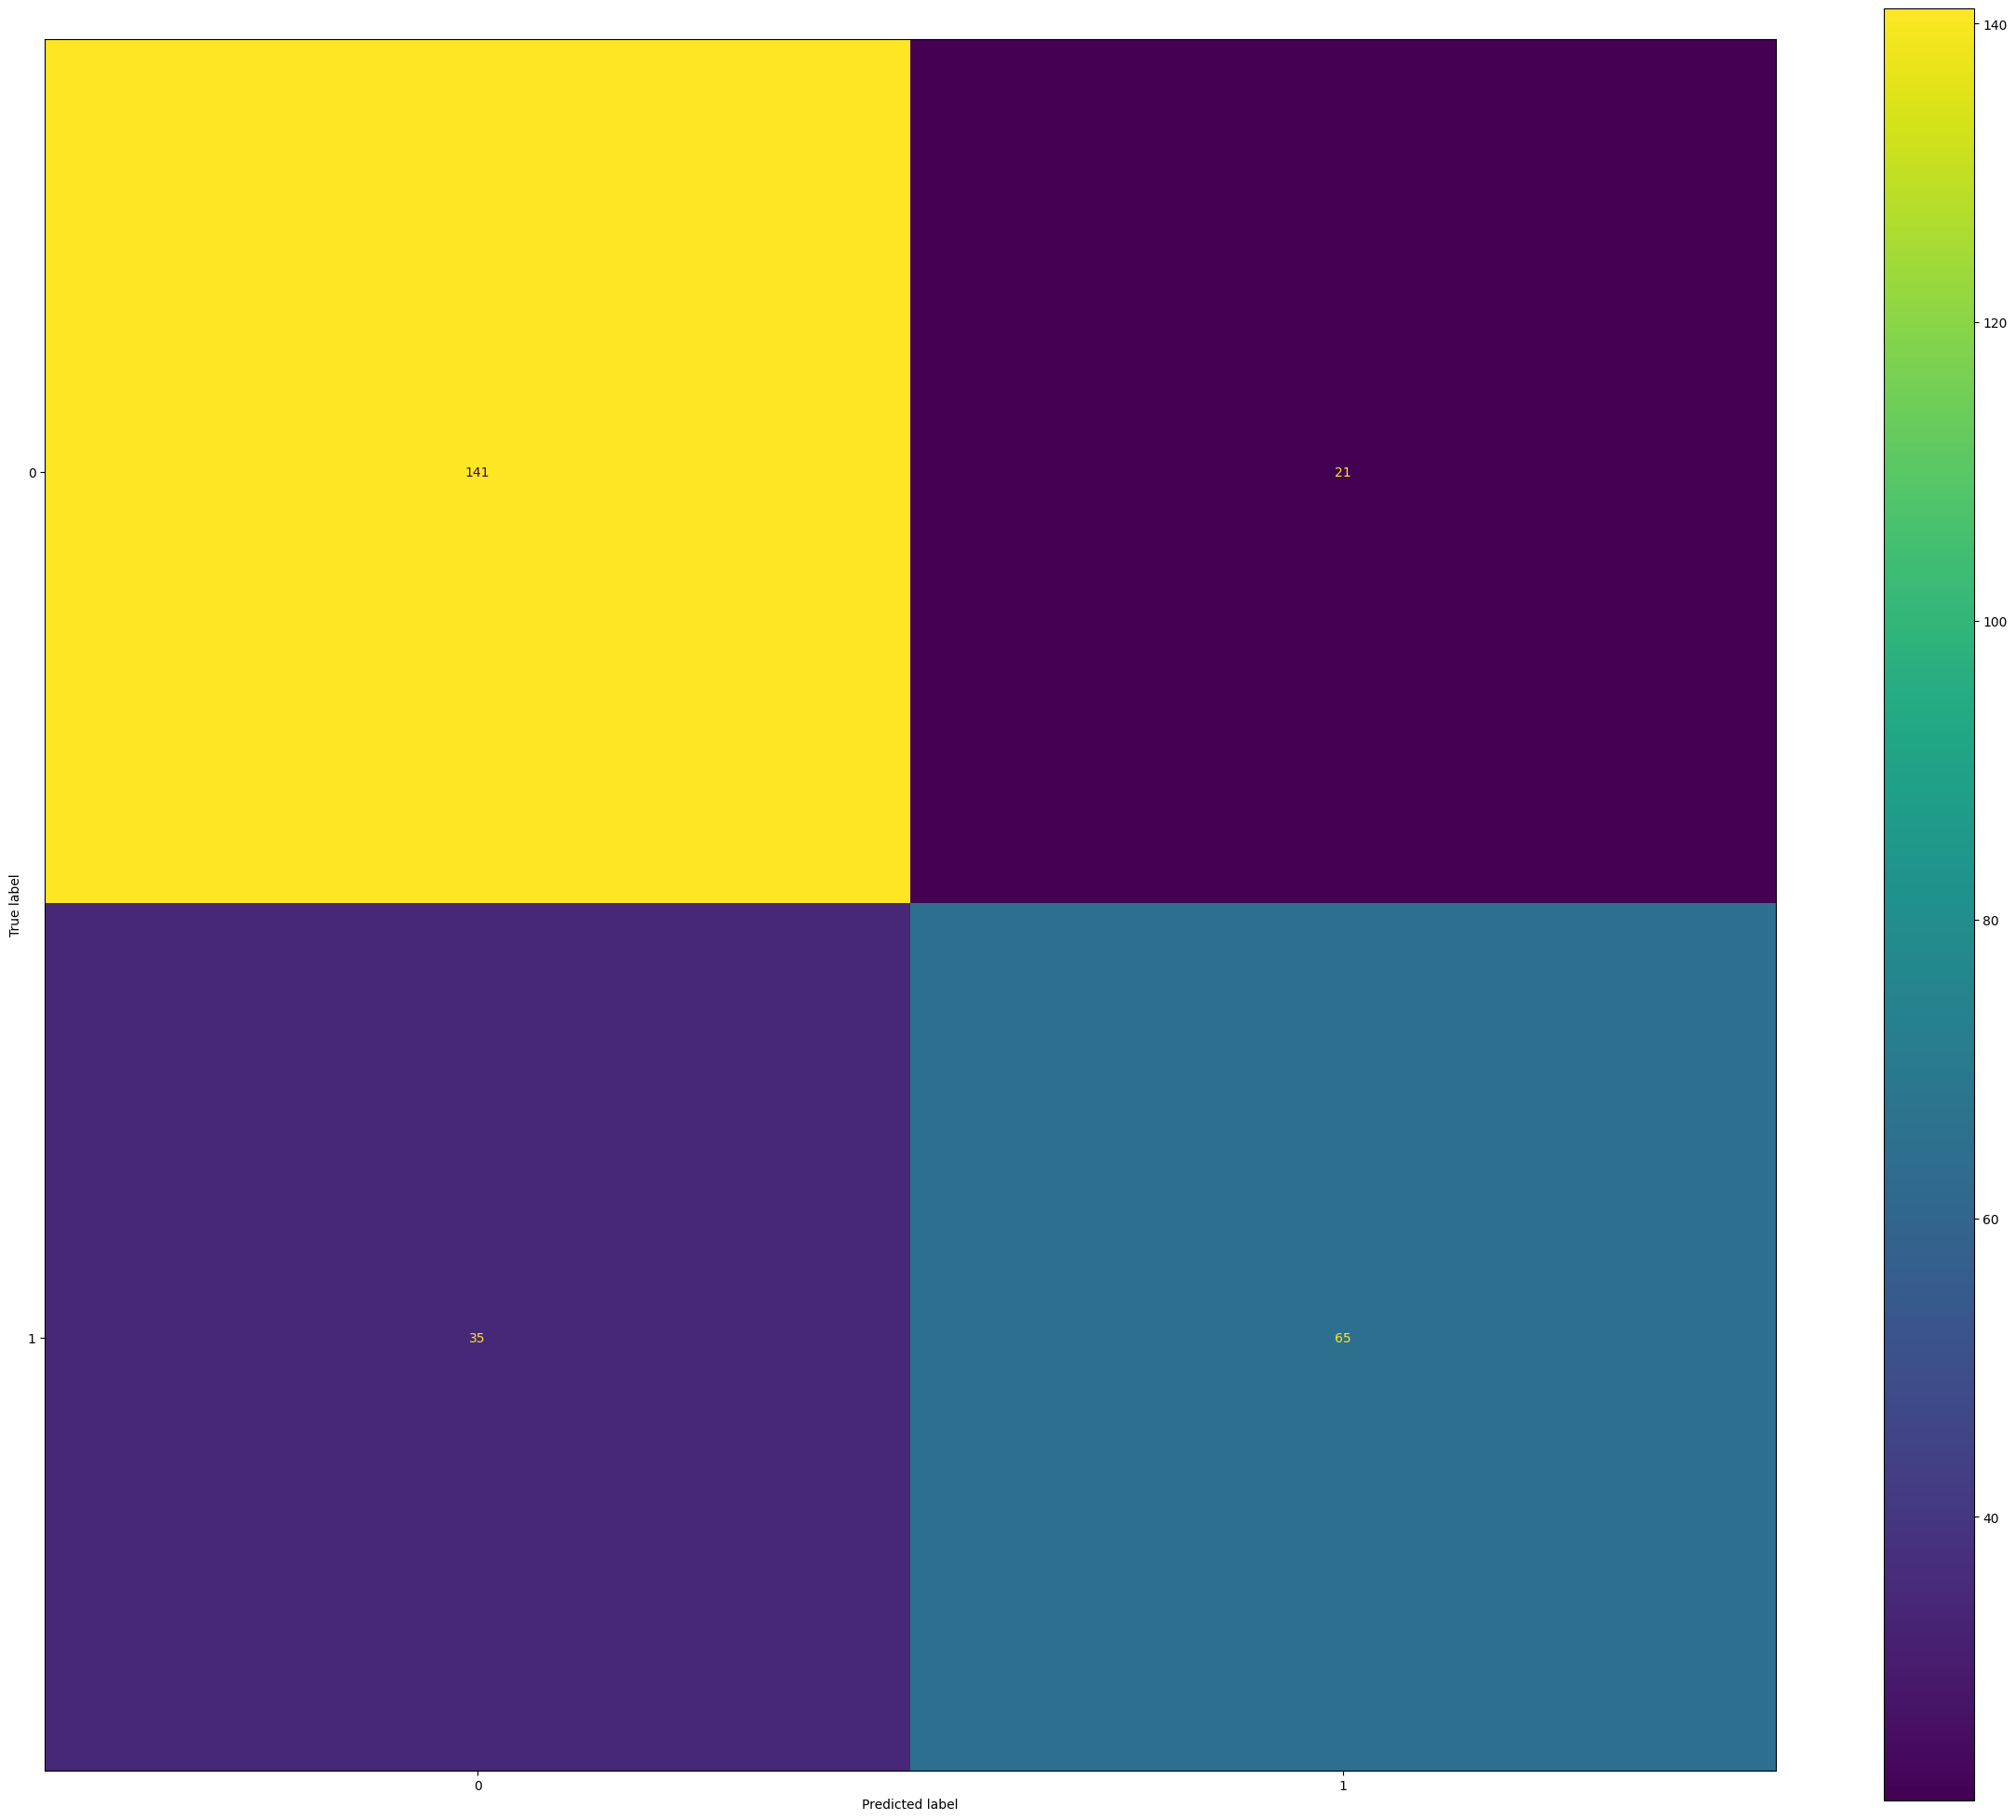

In [180]:
con = confusion_matrix(y_test, gnb.predict(X_test))
disp = ConfusionMatrixDisplay(con)
disp.plot()

Predictions are made on the scaled test dataset using the trained Gaussian Naive Bayes classifier, and a new DataFrame test_df_with_predictions is created by concatenating the original test DataFrame with the predictions DataFrame along the columns.

In [181]:
pred = gnb.predict(test_df_scaled)
predictions_df = pd.DataFrame(pred, index=test_df.index, columns=['Survived'])

# Concatenate the original test DataFrame with the predictions DataFrame along the columns
test_df_with_predictions = pd.concat([test_df, predictions_df], axis=1)

In [182]:
test_df_with_predictions

,pclass,sex,age,embarked,Family,Survived
0,3,1,34,3,1,0
1,3,0,47,1,2,1
2,2,1,62,3,1,0
3,3,1,27,1,1,0
4,3,0,22,1,3,1
5,3,1,14,1,1,0
6,3,0,30,3,1,1
7,2,1,26,1,3,0
8,3,0,18,2,1,1
9,3,1,21,1,3,0


# SVM

The SVM classifier is trained and evaluated on the test set, followed by hyperparameter tuning using grid search. The best hyperparameters are selected, and the tuned model is applied to the testing set for predictions.


In [183]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV


svm_model = SVC()
svm_model.fit(X_train, y_train)
y_pred = svm_model.predict(X_test)


accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy:   {round(accuracy*100,3)} %")
print(f"Precision:  {round(precision*100,3)} %")
print(f"Recall:     {round(recall*100,3)} %")
print(f"F1 Score:   {round(f1*100,3)} %\n\n")

# Experiment with different kernel functions and regularization parameters
param_grid = {'kernel': ['linear', 'poly', 'rbf'],
              'C': [0.1, 1, 10, 100],
              'gamma': ['scale', 'auto']}

grid_search = GridSearchCV(svm_model, param_grid, cv=5)
grid_search.fit(X_train, y_train)

best_svm_model = grid_search.best_estimator_
best_params = grid_search.best_params_

print("Best Hyperparameters:", best_params)

# Apply the tuned model to the testing set for predictions
y_pred_tuned = best_svm_model.predict(X_test)

Accuracy:   80.916 %
Precision:  86.765 %
Recall:     59.0 %
F1 Score:   70.238 %




Best Hyperparameters: {'C': 100, 'gamma': 'scale', 'kernel': 'poly'}


Confusion Matrix Visualization for Tuned SVM Classifier

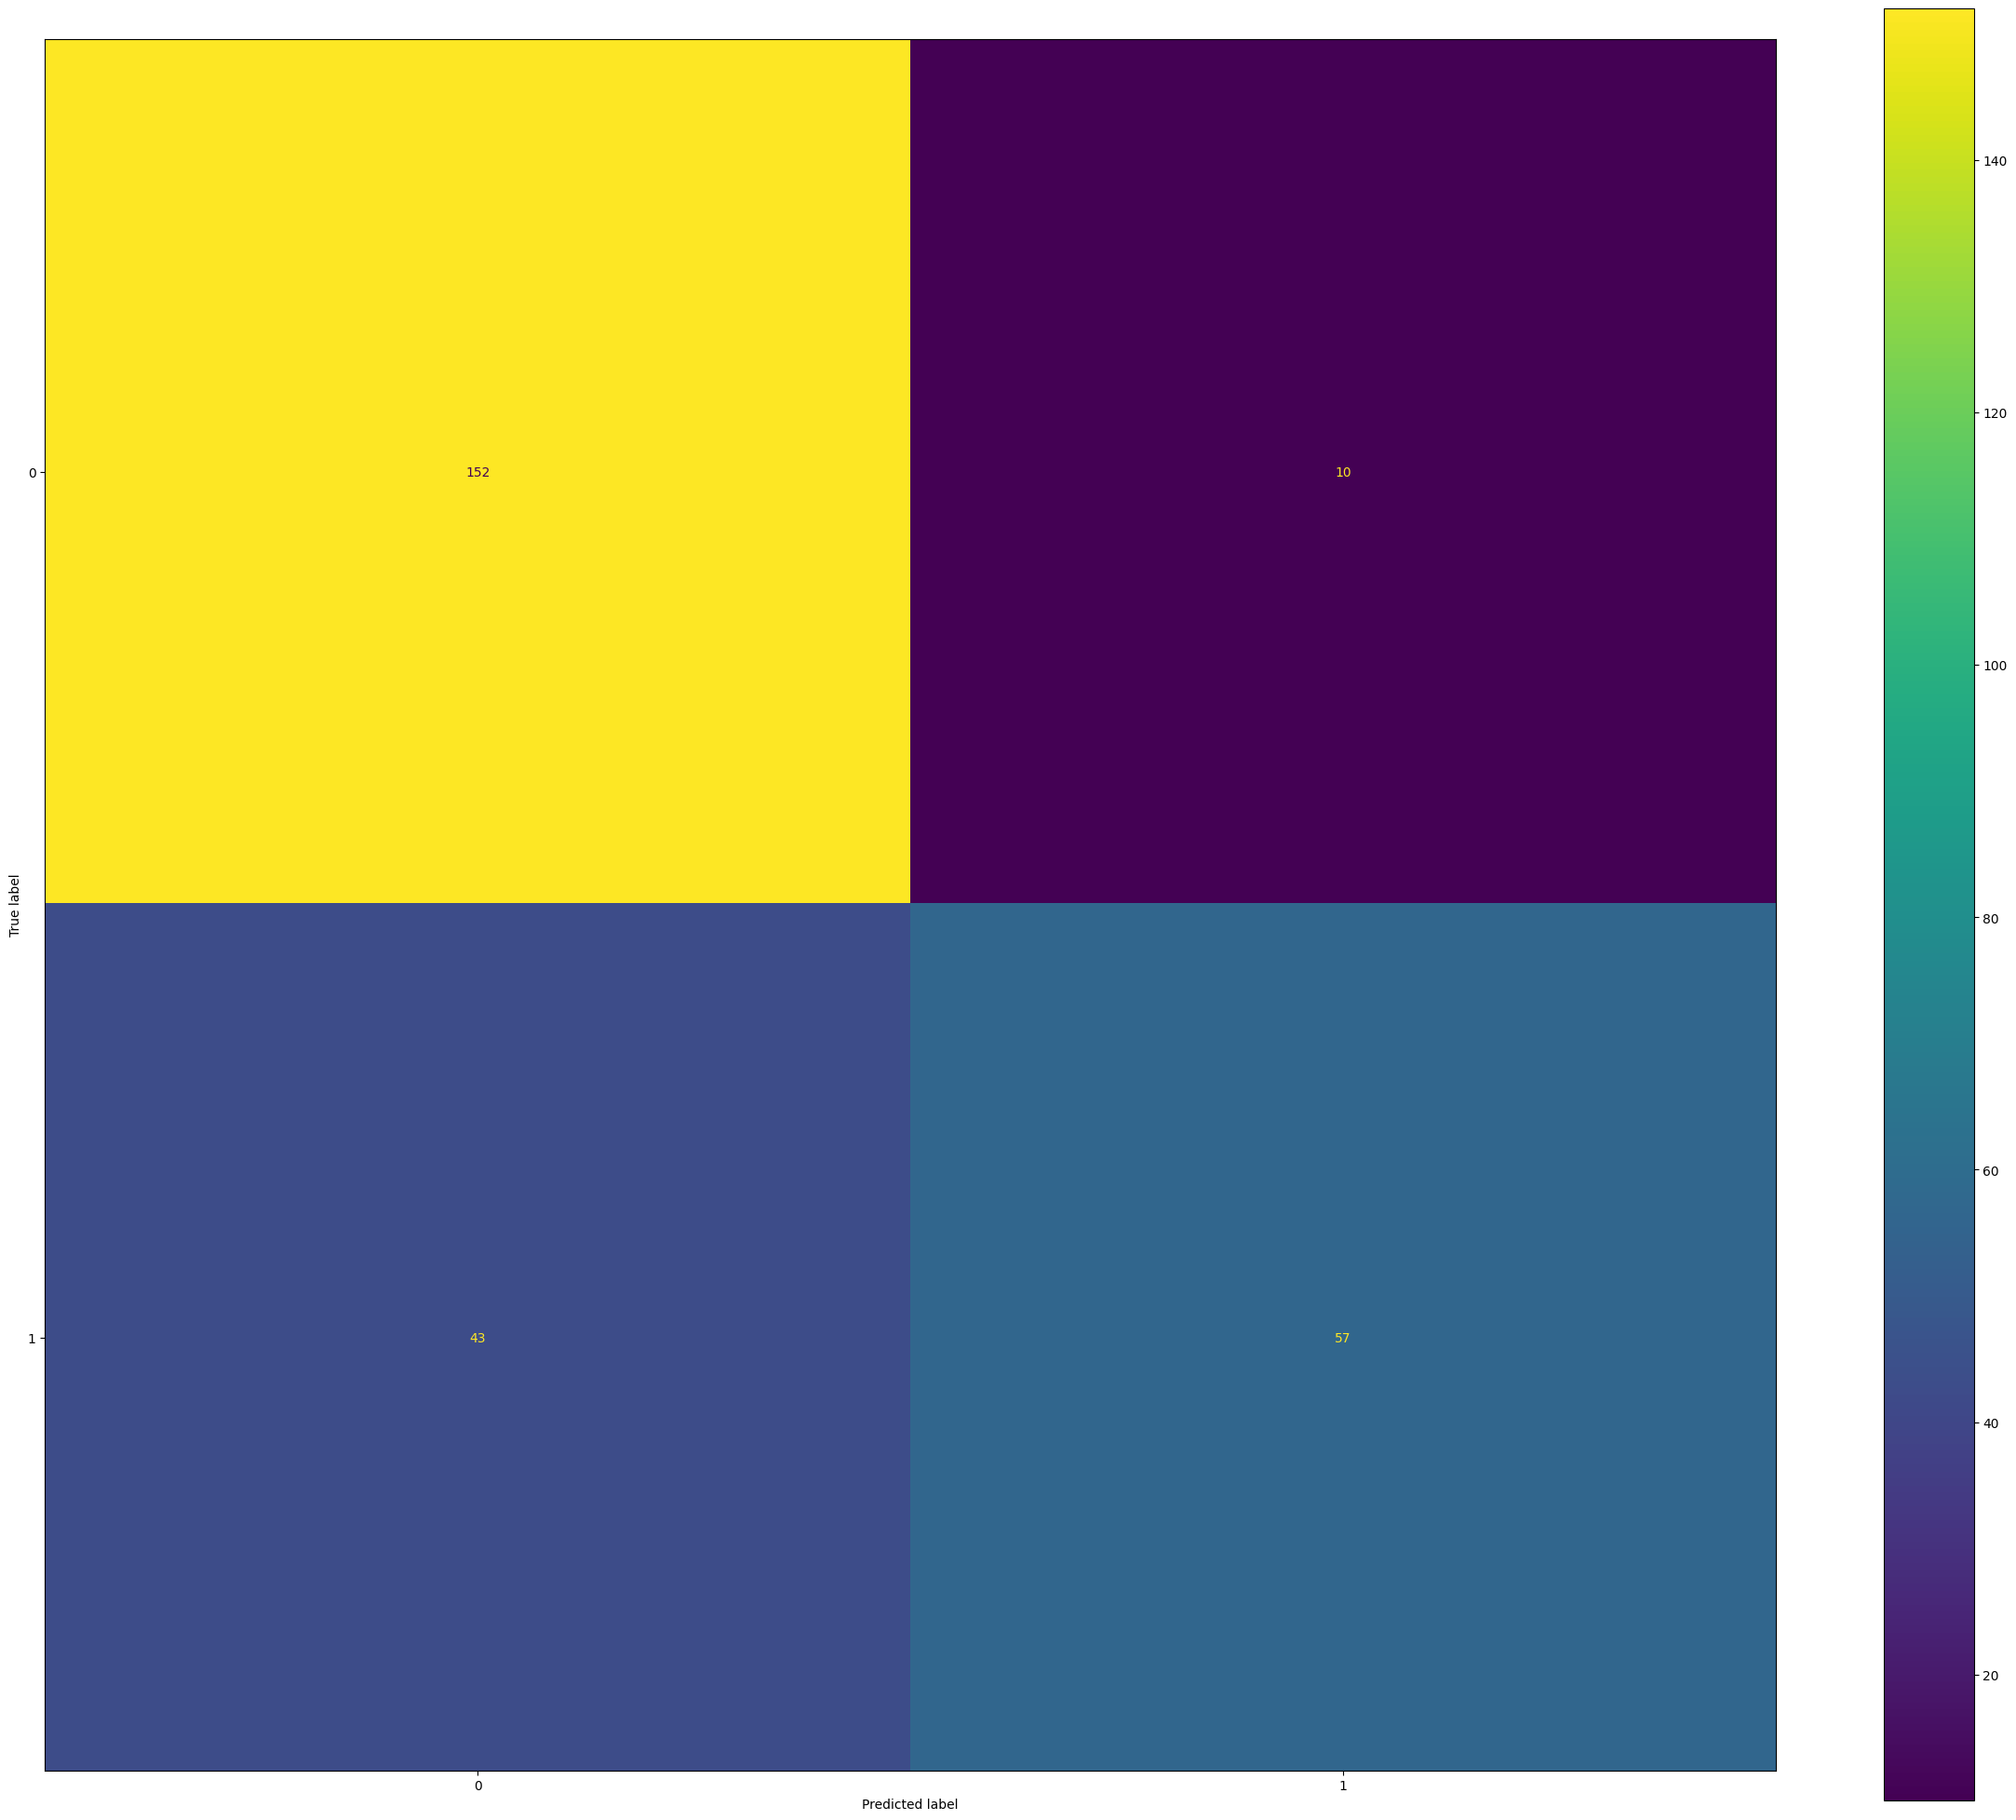

In [184]:
con = confusion_matrix(y_test,y_pred_tuned)
disp = ConfusionMatrixDisplay(con)
disp.plot()

Predictions are made on the scaled test dataset using the tuned SVM classifier, and a new DataFrame test_df_with_predictions is created by concatenating the original test DataFrame with the predictions DataFrame along the columns.


In [185]:
pred = best_svm_model.predict(test_df_scaled)
predictions_df = pd.DataFrame(pred, index=test_df.index, columns=['Survived'])

# Concatenate the original test DataFrame with the predictions DataFrame along the columns
test_df_with_predictions = pd.concat([test_df, predictions_df], axis=1)

In [186]:
test_df_with_predictions

,pclass,sex,age,embarked,Family,Survived
0,3,1,34,3,1,0
1,3,0,47,1,2,0
2,2,1,62,3,1,0
3,3,1,27,1,1,0
4,3,0,22,1,3,0
5,3,1,14,1,1,0
6,3,0,30,3,1,1
7,2,1,26,1,3,0
8,3,0,18,2,1,1
9,3,1,21,1,3,0


# Comparison

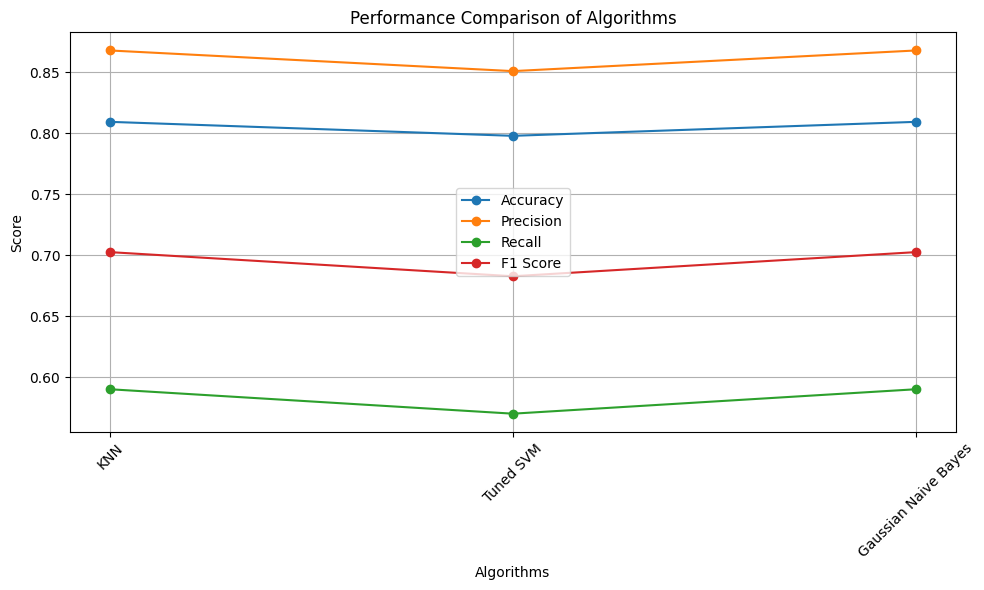

In [187]:
# Define the performance metrics for each algorithm
accuracy_scores = [accuracy_score(y_test, y_pred), accuracy_score(y_test, y_pred_tuned), accuracy_score(y_test, y_pred)]

precision_scores = [precision_score(y_test, y_pred), precision_score(y_test, y_pred_tuned), precision_score(y_test, y_pred)]

recall_scores = [recall_score(y_test, y_pred), recall_score(y_test, y_pred_tuned), recall_score(y_test, y_pred)]

f1_scores = [f1_score(y_test, y_pred), f1_score(y_test, y_pred_tuned), f1_score(y_test, y_pred)]

# Define the algorithms
algorithms = ['KNN', 'Tuned SVM', 'Gaussian Naive Bayes']

# Plotting the performance metrics
plt.figure(figsize=(10, 6))

plt.plot(algorithms, accuracy_scores, marker='o', label='Accuracy')
plt.plot(algorithms, precision_scores, marker='o', label='Precision')
plt.plot(algorithms, recall_scores, marker='o', label='Recall')
plt.plot(algorithms, f1_scores, marker='o', label='F1 Score')

plt.title('Performance Comparison of Algorithms')
plt.xlabel('Algorithms')
plt.ylabel('Score')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Bouns

The Multilayer Perceptron (MLP) classifier is trained and evaluated on the test set, and performance metrics including accuracy, precision, recall, and F1-score are reported.

In [188]:
from sklearn.neural_network import MLPClassifier
mlp_model = MLPClassifier(hidden_layer_sizes=(100, 50), activation='relu', solver='adam', random_state=0)


mlp_model.fit(X_train, y_train)

y_pred = mlp_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy:   {round(accuracy*100,3)} %")
print(f"Precision:  {round(precision*100,3)} %")
print(f"Recall:     {round(recall*100,3)} %")
print(f"F1 Score:   {round(f1*100,3)} %\n\n")

Accuracy:   80.153 %
Precision:  81.579 %
Recall:     62.0 %
F1 Score:   70.455 %




Predictions are made on the scaled test dataset using the Multilayer Perceptron (MLP) classifier, and a new DataFrame "test_df_with_predictions" is created by concatenating the original test DataFrame with the predictions DataFrame along the columns.


In [189]:
pred = mlp_model.predict(test_df_scaled)
predictions_df = pd.DataFrame(pred, index=test_df.index, columns=['Survived'])

# Concatenate the original test DataFrame with the predictions DataFrame along the columns
test_df_with_predictions = pd.concat([test_df, predictions_df], axis=1)

In [190]:
test_df_with_predictions

,pclass,sex,age,embarked,Family,Survived
0,3,1,34,3,1,0
1,3,0,47,1,2,1
2,2,1,62,3,1,0
3,3,1,27,1,1,0
4,3,0,22,1,3,0
5,3,1,14,1,1,0
6,3,0,30,3,1,1
7,2,1,26,1,3,0
8,3,0,18,2,1,1
9,3,1,21,1,3,0
